<a href="https://colab.research.google.com/github/Caliel-Albuquerque/RNA-e-Deep-Learning---CESAR-School-2026.01-A/blob/main/Atividade%202/atividade_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atividade 2 — Regressão linear múltipla: preços de casas na Califórnia

Extensão do notebook **2.6** (salários, uma variável de entrada) para **8 variáveis de entrada**: o modelo passa a ser `nn.Linear(8, 1)`.

## Objetivos

- Aplicar o pipeline do 2.6 (`nn.Linear`, `nn.MSELoss`, `optim.SGD`, `train_epoch`/`validate_epoch`) a um problema com 8 entradas.
- Separar os dados em **treino, validação e teste** (70/15/15) com `random_state` fixo.
- Padronizar entradas e saída com `StandardScaler` ajustado **só no treino**.
- Medir o RMSE no teste **em dólares** e comparar com um baseline.
- Interpretar os 8 pesos aprendidos.

O que muda em relação ao 2.6: há 8 entradas em vez de 1, surge um terceiro conjunto (teste) e a interpretação dos pesos passa a ser uma pergunta em si.

## Importação das bibliotecas

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
from torch import nn, optim

torch.manual_seed(1234)
np.random.seed(1234)

## 1. Análise dos dados

### Carregamento

O dataset *California Housing* vem no scikit-learn e baixa sem login. São 20.640 registros do censo americano de 1990.

In [2]:
dados = fetch_california_housing(as_frame=True)
X, y = dados.data, dados.target   # 20.640 quarteirões, 8 variáveis; y em centenas de milhares de dólares

FEATURES = list(X.columns)
print('X:', X.shape, ' y:', y.shape)
print('variáveis:', FEATURES)
print('alvo:', y.name)
X.head()

X: (20640, 8)  y: (20640,)
variáveis: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
alvo: MedHouseVal


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [4]:
print('entradas')
display(X.describe().T)

print('alvo (em centenas de milhares de US$)')
display(y.describe().to_frame())

print(f'preço médio: US$ {y.mean() * 100_000:,.0f}')
print(f'quarteirões no teto de 5,00001 (US$ 500.001): {(y > 4.9999).sum()}')

entradas


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000


alvo (em centenas de milhares de US$)


,MedHouseVal
count,20640.000000
mean,2.068558
std,1.153956
min,0.149990
25%,1.196000
50%,1.797000
75%,2.647250
max,5.000010


preço médio: US$ 206,856
quarteirões no teto de 5,00001 (US$ 500.001): 992


O `describe()` mostra três coisas que vão importar depois:

1. **Escalas muito diferentes** `MedInc` na casa das unidades (0,5 a 15), `Population` na casa dos milhares (3 a 35.682), `Latitude` em graus com amplitude de 9. Sem padronizar, o gradiente descendente precisaria de uma taxa de aprendizado minúscula, e os pesos não seriam comparáveis entre si.
2. **Caudas longas** `AveRooms` tem máximo de ~142 e `AveOccup` de ~1.243, contra medianas de 5,2 e 2,8. São quarteirões atípicos (alojamentos, hotéis, áreas quase vazias), não erros de digitação, mas inflam o desvio padrão e distorcem a padronização.
3. **Alvo truncado** o máximo é exatamente 5,00001, e **992 quarteirões** estão nesse valor. O censo limitou o valor declarado em US$ 500.001. Nenhum modelo consegue prever acima desse teto artificial, e isso vai aparecer como uma falha visível no gráfico de previsto × real.

### Gráficos de dispersão contra o preço

Duas variáveis contra o alvo: a renda mediana (a mais informativa) e a idade das construções (quase sem relação).

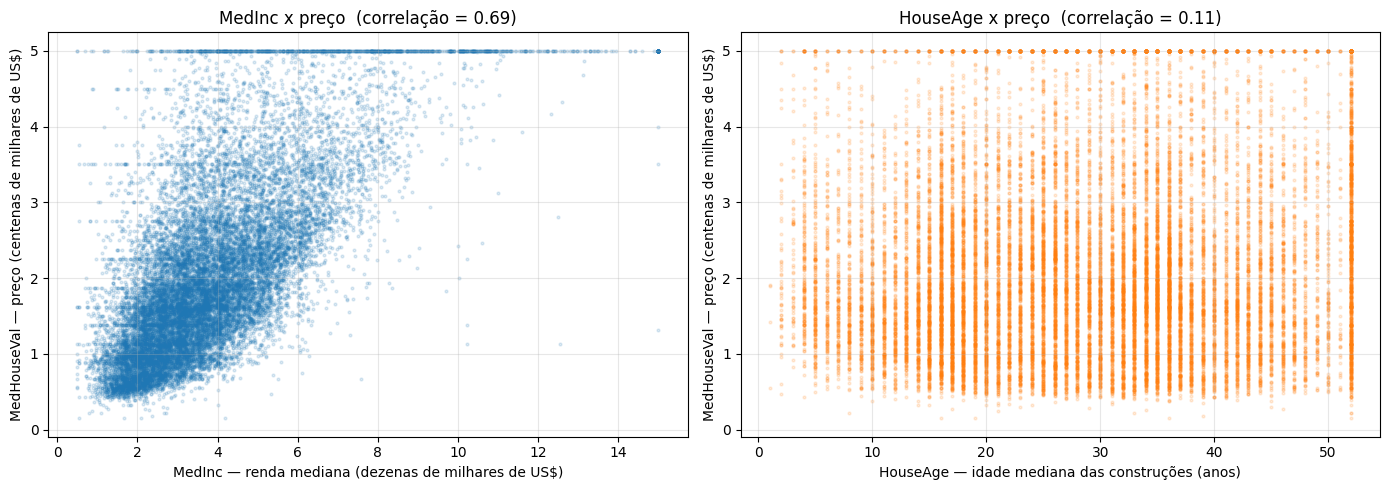

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(X['MedInc'], y, s=4, alpha=0.15)
axes[0].set_xlabel('MedInc — renda mediana (dezenas de milhares de US$)')
axes[0].set_ylabel('MedHouseVal — preço (centenas de milhares de US$)')
axes[0].set_title(f"MedInc x preço  (correlação = {X['MedInc'].corr(y):.2f})")
axes[0].grid(True, alpha=0.3)

axes[1].scatter(X['HouseAge'], y, s=4, alpha=0.15, color='tab:orange')
axes[1].set_xlabel('HouseAge — idade mediana das construções (anos)')
axes[1].set_ylabel('MedHouseVal — preço (centenas de milhares de US$)')
axes[1].set_title(f"HouseAge x preço  (correlação = {X['HouseAge'].corr(y):.2f})")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
# correlacao de todas as variaveis com o preco
X.corrwith(y).sort_values(ascending=False).to_frame('correlação com o preço')

,correlação com o preço
MedInc,0.688075
AveRooms,0.151948
HouseAge,0.105623
AveOccup,-0.023737
Population,-0.024650
Longitude,-0.045967
AveBedrms,-0.046701
Latitude,-0.144160


**Leitura dos gráficos.**

- `MedInc × preço`: relação positiva clara e aproximadamente linear (correlação **0,69**) de longe a variável mais informativa, e é ela que vai sustentar o modelo. A faixa horizontal de pontos no topo é o teto de 5,00001.
- `HouseAge × preço`: nuvem quase sem inclinação (correlação **0,11**). Sozinha, a idade da construção não explica o preço. A barra vertical em 52 anos é a saturação da variável.

Um ponto que os dois gráficos deixam de fora de propósito: a **geografia**. `Latitude` e `Longitude` têm correlação individual baixa (−0,14 e −0,05), mas **combinadas** separam a costa sul (Los Angeles, San Francisco, caríssimas) do Vale Central (barato). É uma relação que não é linear em nenhuma das duas isoladamente e vai ser a maior fonte de erro do modelo.

## 2. Divisão em treino, validação e teste (70/15/15)

O `train_test_split` só divide em dois, então aplicamos duas vezes: primeiro 70% / 30%, depois metade dos 30% para cada conjunto. `random_state=42` fixa o sorteio nas duas chamadas, para que a divisão seja sempre a mesma.

**Por que três conjuntos** (no 2.6 eram dois):

- **treino**  ajusta os 9 parâmetros via gradiente descendente;
- **validação**  mede o custo em dados não vistos *durante* o desenvolvimento, e é onde se decide taxa de aprendizado, número de épocas e quais variáveis usar;
- **teste** tocado **uma única vez**, no fim.

A razão de existir o terceiro conjunto: a partir do momento em que a taxa de aprendizado é escolhida olhando a curva de validação, essa curva deixa de ser uma estimativa imparcial houve otimização contra aquele conjunto. Reportar o resultado nele daria um número otimista. No 2.6 não separamos teste porque havia só 30 amostras; aqui, 15% são mais de 3.000 registros, o suficiente para uma estimativa estável.

In [7]:
X_np = X.to_numpy()
y_np = y.to_numpy().reshape(-1, 1)

X_train_raw, X_tmp, y_train_raw, y_tmp = train_test_split(
    X_np, y_np, test_size=0.30, random_state=42)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=42)

for nome, arr in [('treino', X_train_raw), ('validação', X_val_raw), ('teste', X_test_raw)]:
    print(f'{nome:10s} {str(arr.shape):12s} ({len(arr) / len(X_np):.0%})')

treino     (14448, 8)   (70%)
validação  (3096, 8)    (15%)
teste      (3096, 8)    (15%)


## 3. Padronização (ajustada só no treino)

$$z = \frac{x - \mu}{\sigma}$$

Um `StandardScaler` para as 8 entradas ele calcula $\mu$ e $\sigma$ **coluna por coluna** e outro para a saída. Ambos recebem `fit` **apenas no treino**; validação e teste passam só por `transform`.

Se $\mu$ e $\sigma$ fossem calculados com todos os dados, informação dos conjuntos de avaliação entraria no treino (vazamento de dados) e as estimativas de erro deixariam de valer. É a mesma regra do 2.6, agora com 8 colunas.

In [8]:
x_scaler = StandardScaler().fit(X_train_raw)
y_scaler = StandardScaler().fit(y_train_raw)

to_tensor = lambda scaler, arr: torch.from_numpy(scaler.transform(arr)).float()

x_train, y_train = to_tensor(x_scaler, X_train_raw), to_tensor(y_scaler, y_train_raw)
x_val,   y_val   = to_tensor(x_scaler, X_val_raw),   to_tensor(y_scaler, y_val_raw)
x_test,  y_test  = to_tensor(x_scaler, X_test_raw),  to_tensor(y_scaler, y_test_raw)

print('x_train:', x_train.shape, ' y_train:', y_train.shape)
print('x_val:  ', x_val.shape, '  y_val:  ', y_val.shape)
print('x_test: ', x_test.shape, '  y_test: ', y_test.shape)

pd.DataFrame({'variável': FEATURES,
              'mu (treino)': x_scaler.mean_,
              'sigma (treino)': x_scaler.scale_})

x_train: torch.Size([14448, 8])  y_train: torch.Size([14448, 1])
x_val:   torch.Size([3096, 8])   y_val:   torch.Size([3096, 1])
x_test:  torch.Size([3096, 8])   y_test:  torch.Size([3096, 1])


,variável,mu (treino),sigma (treino)
0,MedInc,3.876892,1.904842
1,HouseAge,28.575374,12.613197
2,AveRooms,5.438125,2.453484
3,AveBedrms,1.098033,0.447482
4,Population,1427.927326,1140.185729
5,AveOccup,3.119236,12.373207
6,Latitude,35.650669,2.135668
7,Longitude,-119.584102,2.002861


## 4. Treinamento

### Modelo

`nn.Linear(8, 1)` calcula $\hat{y} = w_0 + \sum_{j=1}^{8} w_j x_j$:

- `model.weight`, shape **(1, 8)**, guarda os 8 pesos;
- `model.bias`, shape (1,), é o $w_0$.

São 9 parâmetros. A única diferença de código em relação ao 2.6 é o `8` no lugar do `1`.

In [9]:
model = nn.Linear(8, 1)
print('weight:', model.weight.shape, ' bias:', model.bias.shape)
print('total de parâmetros:', sum(p.numel() for p in model.parameters()))

# teste rapido do forward
with torch.no_grad():
    print('previsão para as 3 primeiras amostras:', model(x_train[:3]).ravel())

weight: torch.Size([1, 8])  bias: torch.Size([1])
total de parâmetros: 9
previsão para as 3 primeiras amostras: tensor([0.3319, 0.9249, 0.4498])


### Função de custo e otimizador

In [10]:
lr = 0.1
n_epochs = 600

criterion = nn.MSELoss()
optimizer = optim.SGD(model.parameters(), lr=lr)

### Funções de treino e de validação

As mesmas do 2.6. `train_epoch` faz um passo de gradiente descendente com todo o conjunto de treino e devolve o custo; `evaluate` só mede, sem atualizar nada com `model.eval()` e `torch.no_grad()`.

In [11]:
def train_epoch(model, optimizer, criterion, x_train, y_train):
    model.train()
    optimizer.zero_grad()

    y_pred = model(x_train)
    loss = criterion(y_pred, y_train)

    loss.backward()
    optimizer.step()

    return loss.item()


def evaluate(model, criterion, x, y):
    model.eval()
    with torch.no_grad():
        return criterion(model(x), y).item()

### Laço de treinamento

In [12]:
train_losses, val_losses = [], []

for epoch in range(n_epochs):
    train_losses.append(train_epoch(model, optimizer, criterion, x_train, y_train))
    val_losses.append(evaluate(model, criterion, x_val, y_val))

    if (epoch + 1) % 100 == 0:
        print(f'Epoch[{epoch + 1}/{n_epochs}], '
              f'Train Loss: {train_losses[-1]:.6f}, Val Loss: {val_losses[-1]:.6f}')

Epoch[100/600], Train Loss: 0.393754, Val Loss: 0.406560
Epoch[200/600], Train Loss: 0.390795, Val Loss: 0.403884
Epoch[300/600], Train Loss: 0.390663, Val Loss: 0.403760
Epoch[400/600], Train Loss: 0.390655, Val Loss: 0.403742
Epoch[500/600], Train Loss: 0.390654, Val Loss: 0.403735
Epoch[600/600], Train Loss: 0.390654, Val Loss: 0.403732


### Curvas de custo de treino e de validação

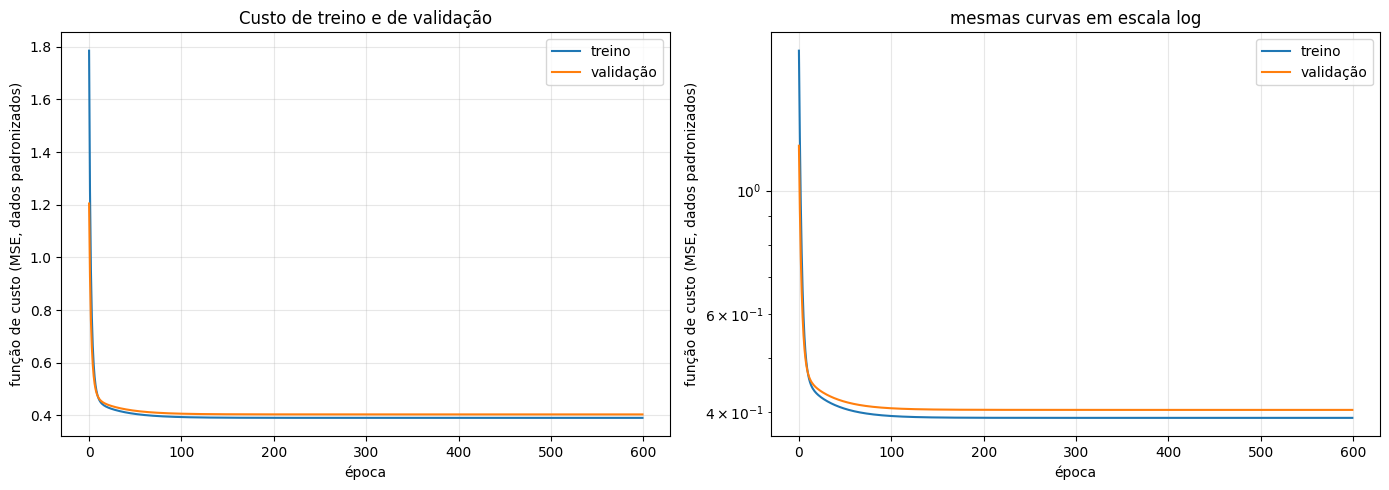

MSE final  treino: 0.3907   validação: 0.4037


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, logy in zip(axes, [False, True]):
    ax.plot(range(n_epochs), train_losses, label='treino')
    ax.plot(range(n_epochs), val_losses, label='validação')
    ax.set_xlabel('época')
    ax.set_ylabel('função de custo (MSE, dados padronizados)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    if logy:
        ax.set_yscale('log')
        ax.set_title('mesmas curvas em escala log')
    else:
        ax.set_title('Custo de treino e de validação')

plt.tight_layout()
plt.show()

print(f'MSE final  treino: {train_losses[-1]:.4f}   validação: {val_losses[-1]:.4f}')

As duas curvas caem juntas e estacionam quase no mesmo patamar (≈ 0,39 no treino, ≈ 0,41 na validação). A distância mínima entre elas diz que **não há overfitting**: com 9 parâmetros e 14 mil amostras de treino, não há como decorar os dados.

O problema é o oposto o custo para alto. O hiperplano é rígido demais para a relação real. Isso é **underfitting** (viés alto), e o caminho para melhorar é um modelo mais expressivo, não mais regularização.

## 5. RMSE no teste, em dólares, contra o baseline

O MSE acima está na escala padronizada. Para ler em dólares são dois passos: `inverse_transform` traz as previsões de volta à escala do alvo (centenas de milhares), e a multiplicação por 100.000 converte para dólares.

$$\text{RMSE} = \sqrt{\frac{1}{M}\sum_{i=1}^{M}\left(\hat{y}^{(i)} - y^{(i)}\right)^2}$$

O **baseline** é o modelo mais bobo que respeita as regras: ignora as 8 entradas e prevê sempre a média do preço **no treino** (nunca a média geral isso seria vazamento). É a referência honesta: qualquer modelo precisa bater isso para ter valor.

In [14]:
model.eval()
with torch.no_grad():
    y_test_pred = model(x_test)

y_test_pred_raw = y_scaler.inverse_transform(y_test_pred.numpy())   # centenas de milhares

rmse_test = np.sqrt(((y_test_pred_raw - y_test_raw) ** 2).mean())
mae_test = np.abs(y_test_pred_raw - y_test_raw).mean()

baseline_pred = y_train_raw.mean()                       # media do TREINO
rmse_baseline = np.sqrt(((baseline_pred - y_test_raw) ** 2).mean())

r2 = 1 - ((y_test_pred_raw - y_test_raw) ** 2).sum() / \
         ((y_test_raw - y_test_raw.mean()) ** 2).sum()

D = 100_000   # o alvo esta em centenas de milhares de dolares

print(f'baseline (média do treino) : US$ {baseline_pred * D:,.0f}')
print()
print(f'RMSE do baseline no teste  : US$ {rmse_baseline * D:,.0f}')
print(f'RMSE do modelo   no teste  : US$ {rmse_test * D:,.0f}')
print(f'redução do erro            : {1 - rmse_test / rmse_baseline:.1%}')
print()
print(f'MAE do modelo no teste     : US$ {mae_test * D:,.0f}')
print(f'R² no teste                : {r2:.3f}')
print(f'previsões negativas        : {(y_test_pred_raw < 0).sum()} de {len(y_test_pred_raw)}')

baseline (média do treino) : US$ 206,924

RMSE do baseline no teste  : US$ 114,992
RMSE do modelo   no teste  : US$ 72,130
redução do erro            : 37.3%

MAE do modelo no teste     : US$ 52,104
R² no teste                : 0.607
previsões negativas        : 7 de 3096


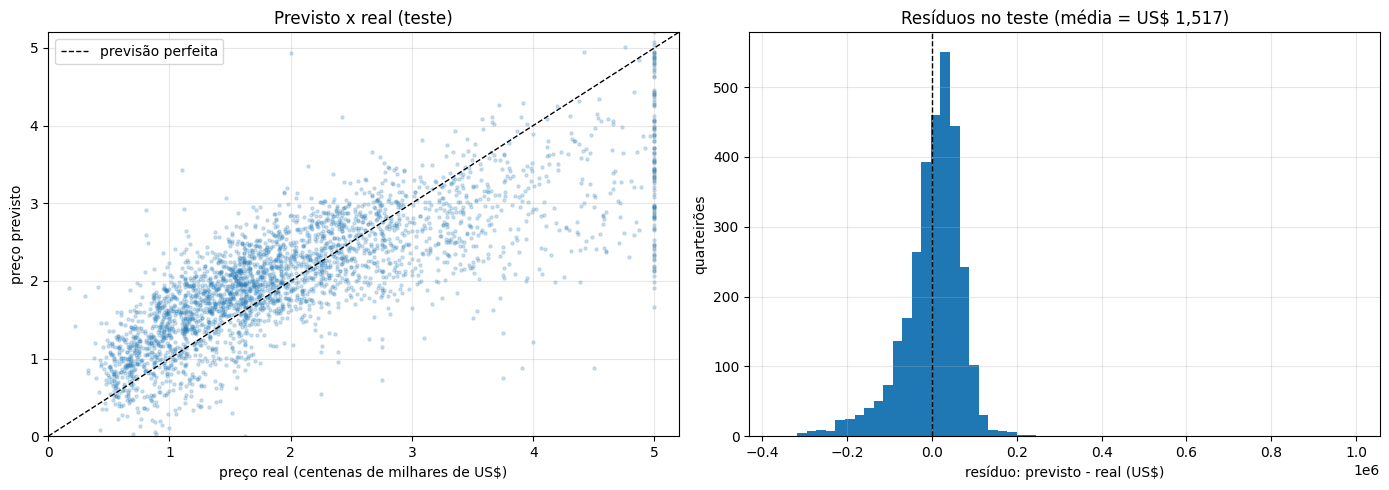

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

lim = [0, 5.2]
axes[0].scatter(y_test_raw, y_test_pred_raw, s=5, alpha=0.2)
axes[0].plot(lim, lim, 'k--', lw=1, label='previsão perfeita')
axes[0].set_xlabel('preço real (centenas de milhares de US$)')
axes[0].set_ylabel('preço previsto')
axes[0].set_title('Previsto x real (teste)')
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].legend(); axes[0].grid(True, alpha=0.3)

res = (y_test_pred_raw - y_test_raw).ravel() * D
axes[1].hist(res, bins=60)
axes[1].axvline(0, color='k', ls='--', lw=1)
axes[1].set_xlabel('resíduo: previsto - real (US$)')
axes[1].set_ylabel('quarteirões')
axes[1].set_title(f'Resíduos no teste (média = US$ {res.mean():,.0f})')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

O gráfico previsto × real expõe duas falhas estruturais:

- a **coluna de pontos em 5,0** o teto do censo, que o modelo espalha entre ~2 e ~4,5, porque nada nos dados sinaliza que aquele valor é artificial;
- **previsões negativas** para os quarteirões mais baratos. Nada num modelo linear impede $\hat{y} < 0$, e um preço negativo não existe.

Os resíduos são aproximadamente centrados em zero (o modelo não é viesado para cima ou para baixo no agregado), mas com cauda longa à direita: os erros grandes vêm sobretudo dos imóveis caros.

## 6. Os 8 pesos aprendidos

In [16]:
w = model.weight.detach().numpy().ravel()
sigma_y = y_scaler.scale_[0]

pesos = (pd.DataFrame({
            'variável': FEATURES,
            'peso (padronizado)': w,
            'efeito de +1 desvio padrão (US$)': w * sigma_y * D})
         .sort_values('peso (padronizado)', ascending=False)
         .reset_index(drop=True))

print(f'bias (w0): {model.bias.item():.2e}')
print(f'sigma_y: {sigma_y:.4f}  (US$ {sigma_y * D:,.0f})')
pesos

bias (w0): 1.33e-08
sigma_y: 1.1575  (US$ 115,745)


,variável,peso (padronizado),efeito de +1 desvio padrão (US$)
0,MedInc,0.733827,84937.027374
1,AveBedrms,0.301199,34862.368933
2,HouseAge,0.105538,12215.466806
3,Population,-0.000754,-87.302210
4,AveOccup,-0.036032,-4170.561962
5,AveRooms,-0.259039,-29982.476816
6,Longitude,-0.750138,-86824.870864
7,Latitude,-0.771929,-89347.052451


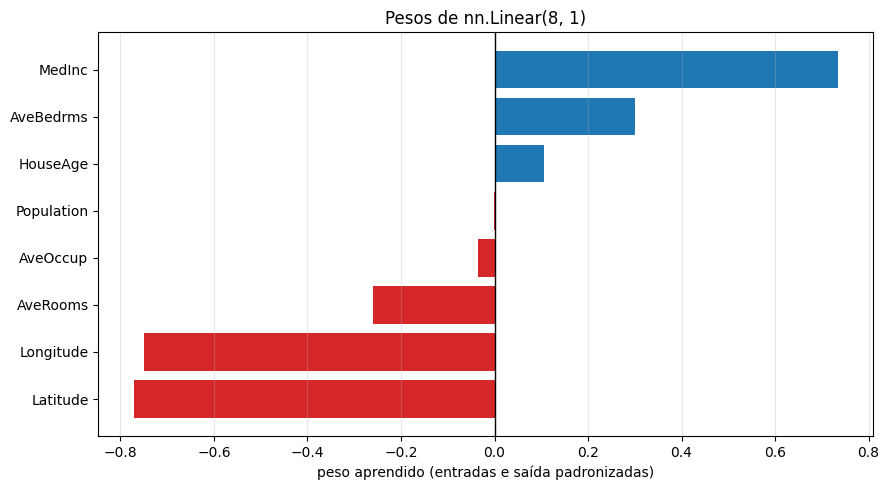

In [17]:
ordem = np.argsort(w)
cores = ['tab:red' if v < 0 else 'tab:blue' for v in w[ordem]]

plt.figure(figsize=(9, 5))
plt.barh([FEATURES[i] for i in ordem], w[ordem], color=cores)
plt.axvline(0, color='k', lw=1)
plt.xlabel('peso aprendido (entradas e saída padronizadas)')
plt.title('Pesos de nn.Linear(8, 1)')
plt.grid(True, axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### Por que só faz sentido comparar os pesos entre si porque as entradas foram padronizadas

Na escala original, cada peso tem a unidade **"preço por unidade da variável"**, e as unidades são incomparáveis entre si:

- o peso de `Population` estaria em "dólares por habitante", e a variável varia por **dezenas de milhares** de unidades;
- o peso de `Latitude` estaria em "dólares por grau", e a variável varia por **9** unidades no total;
- o peso de `MedInc` estaria em "dólares por dezena de milhar de dólares de renda".

Um peso numericamente minúsculo em `Population` poderia representar um efeito enorme, justamente porque a variável percorre milhares de unidades. Um peso numericamente grande em `Latitude` poderia ser irrelevante, porque a variável quase não varia. **Comparar números com unidades diferentes não significa nada** é como perguntar se 3 metros é maior que 5 quilos.

Depois do `StandardScaler`, todas as entradas estão na mesma unidade **desvios padrão** e a saída também. Cada peso passa a responder exatamente à mesma pergunta para todas as variáveis:

> *quantos desvios padrão de preço o modelo move quando esta variável sobe um desvio padrão, mantendo as outras sete fixas?*

É isso que torna o ranking legítimo, e é também por isso que multiplicar o peso por $\sigma_y$ (e por 100.000) devolve o efeito em dólares. A padronização transformou os pesos em uma medida de **importância relativa**.

Dois cuidados que a padronização **não** resolve:

1. o peso continua sendo um efeito **parcial**, condicionado às outras sete variáveis não é o efeito total da variável sozinha (compare o peso de `AveRooms`, negativo, com sua correlação simples com o preço, que é **positiva**: +0,15);
2. sob **colinearidade**, a divisão do crédito entre variáveis correlacionadas é instável é o caso de `AveRooms`/`AveBedrms` e de `Latitude`/`Longitude`. Remover uma delas mudaria bastante o peso da outra.

## 7. Conclusão

**O modelo é bom o suficiente?** Depende para quê mas, para avaliar imóveis, **não**.

O que ele tem de bom: bate o baseline com folga RMSE de ≈ **US$ 72 mil** contra ≈ **US$ 115 mil** do "prever sempre a média", ou seja, **≈ 37% menos erro**, com R² ≈ 0,61. E faz isso com 9 parâmetros, treino em segundos e pesos legíveis. Como referência de partida e como diagnóstico de quais variáveis importam, cumpre bem o papel.

O que o inviabiliza na prática: um erro típico de US$ 72 mil sobre um preço médio de US$ 207 mil é cerca de **35%**. Ninguém decide uma compra, um financiamento ou um imposto com essa margem. E os erros não são aleatórios — são **sistemáticos**: o modelo prevê valores negativos para os quarteirões mais baratos, achata o teto de US$ 500.001 e erra por região. Isso indica que a *forma* do modelo está errada, não que faltam dados. As curvas de treino e validação quase coladas confirmam: o problema é **underfitting**, não overfitting.

**O que eu tentaria, em ordem de custo-benefício:**

1. **Tratar o alvo truncado** remover ou modelar separadamente os 992 quarteirões em 5,00001. Hoje eles puxam o ajuste de todo o resto para cima.
2. **Prever `log(preço)`**  o preço é positivo e assimétrico; o log elimina as previsões negativas por construção e transforma os erros em termos relativos, que é como se raciocina sobre preço de imóvel.
3. **Aparar os outliers** de `AveRooms` e `AveOccup` (máximos de 142 e 1.243 contra medianas de 5 e 3), que distorcem a padronização e dominam o MSE.
4. **Trocar a geografia por algo não-linear** distância até a costa e até os grandes centros, ou latitude/longitude em *bins* cruzados. É a maior fonte de erro estrutural, e duas retas não dão conta dela.
5. **Dar não-linearidade ao modelo** interações e termos quadráticos, ou, o caminho natural do curso, uma **MLP** com uma ou duas camadas escondidas e ReLU. Com 14 mil amostras de treino há folga de dados, e só aí passa a fazer sentido vigiar a curva de validação em busca de overfitting.
6. **Ajustes de treino** mini-batches, Adam no lugar do SGD puro. Melhoram a convergência, mas **não mudam o teto** do modelo linear: são os itens 1 a 5 que mexem no resultado.